# Chest X-ray Data EDA and Visualization

Explore the prepared image dataset: class balance by split, readable-image counts, image dimensions and modes, sample images, and grayscale pixel intensities.

Expected layout: `chest_xray_cnn_splits/{train,val,test}/{NORMAL,PNEUMONIA}/`. If your data is elsewhere, update `DATA_DIR` in the setup cell. Run the data preparation notebook first if these split folders have not been created.

In [5]:
from collections import Counter
from pathlib import Path
import os
import subprocess
import sys
import random

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, UnidentifiedImageError

SEED = 42
SPLIT_NAMES = ("train", "val", "test")
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}
SAMPLE_IMAGES_PER_CLASS = 3

# Set this to the folder containing train/, val/, and test/ if needed.
PROJECT_ROOT = next(
    (parent for parent in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     if (parent / "requirements.txt").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Start Jupyter from this project or set PROJECT_ROOT explicitly.")
DATA_DIR = Path("chest_xray_cnn_splits")
OUTPUT_PATH = PROJECT_ROOT / "results" / "data_eda" / "current_split_data_eda.png"
random.seed(SEED)
np.random.seed(SEED)

# Search the current project and the default KaggleHub cache used by the
# preparation notebook. Its output folder is created in KaggleHub's versions/.
data_dir_candidates = [
    PROJECT_ROOT / DATA_DIR,
    *(parent / DATA_DIR.name for parent in PROJECT_ROOT.parents),
]
kagglehub_cache = Path(
    os.environ.get("KAGGLEHUB_CACHE", Path.home() / ".cache" / "kagglehub")
)
dataset_versions = (
    kagglehub_cache
    / "datasets"
    / "paultimothymooney"
    / "chest-xray-pneumonia"
    / "versions"
)
data_dir_candidates.append(dataset_versions / DATA_DIR.name)
data_dir_candidates.extend(dataset_versions.glob(f"*/{DATA_DIR.name}"))

DATA_DIR = next((path for path in data_dir_candidates if path.is_dir()), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not find the prepared chest_xray_cnn_splits folder. Run "
        "notebooks/01_data_preparation/01_chest_xray_train_val_test_split.ipynb first, then set DATA_DIR here "
        "to the 'Split folders' path printed by that notebook."
    )
subprocess.run([sys.executable, str(PROJECT_ROOT / "src" / "data" / "validate_dataset.py"), "--split-dir", str(DATA_DIR)], check=True)
print(f"Dataset directory: {DATA_DIR.resolve()}")

Dataset directory: C:\Users\apsur\.cache\kagglehub\datasets\paultimothymooney\chest-xray-pneumonia\versions\chest_xray_cnn_splits


In [6]:
# Find image files in each available split and class folder.
records = {}
for split in SPLIT_NAMES:
    split_dir = DATA_DIR / split
    if not split_dir.is_dir():
        print(f"Split not found (skipping): {split_dir}")
        continue

    records[split] = {
        class_dir.name: sorted(
            path for path in class_dir.rglob("*")
            if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
        )
        for class_dir in sorted(split_dir.iterdir())
        if class_dir.is_dir()
    }

if not any(paths for classes in records.values() for paths in classes.values()):
    raise FileNotFoundError(
        f"No supported images found under {DATA_DIR} in train/val/test class folders."
    )

class_names = sorted({name for classes in records.values() for name in classes})
print("Classes:", class_names)
print("Splits:", list(records))

Classes: ['NORMAL', 'PNEUMONIA']
Splits: ['train', 'val', 'test']


In [7]:
# Validate image readability and collect basic metadata.
valid_records = {split: {} for split in records}
counts = Counter()
image_modes = Counter()
image_dimensions = []
corrupt_files = []
samples = []
rng = random.Random(SEED)

for split, classes in records.items():
    for class_name, paths in classes.items():
        valid_paths = []
        for image_path in paths:
            try:
                with Image.open(image_path) as image:
                    image.verify()
                with Image.open(image_path) as image:
                    image_dimensions.append(image.size)  # (width, height)
                    image_modes[image.mode] += 1
                valid_paths.append(image_path)
            except (OSError, UnidentifiedImageError) as error:
                corrupt_files.append((image_path, str(error)))

        valid_records[split][class_name] = valid_paths
        counts[(split, class_name)] = len(valid_paths)
        chosen = rng.sample(valid_paths, min(SAMPLE_IMAGES_PER_CLASS, len(valid_paths)))
        samples.extend((split, class_name, path) for path in chosen)

print(f"Readable images: {sum(counts.values()):,}")
print(f"Unreadable images: {len(corrupt_files):,}")
if corrupt_files:
    for path, error in corrupt_files[:20]:
        print(f"  {path}: {error}")
    if len(corrupt_files) > 20:
        print(f"  ... and {len(corrupt_files) - 20:,} more")

Readable images: 5,824
Unreadable images: 0


In [8]:
# Print per-split class counts and dataset-wide image metadata.
header = f"{'Split':<10}" + "".join(f"{name:>14}" for name in class_names) + f"{'Total':>10}"
print("Valid image counts")
print(header)
for split in valid_records:
    row = [counts[(split, name)] for name in class_names]
    print(f"{split:<10}" + "".join(f"{count:>14,}" for count in row) + f"{sum(row):>10,}")

if image_dimensions:
    widths, heights = zip(*image_dimensions)
    print(f"\nWidth range: {min(widths)}–{max(widths)} pixels")
    print(f"Height range: {min(heights)}–{max(heights)} pixels")
print("Image modes:", dict(image_modes))

Valid image counts
Split             NORMAL     PNEUMONIA     Total
train              1,213         3,475     4,688
val                  135           383       518
test                 231           387       618

Width range: 384–2916 pixels
Height range: 127–2713 pixels
Image modes: {'L': 5541, 'RGB': 283}


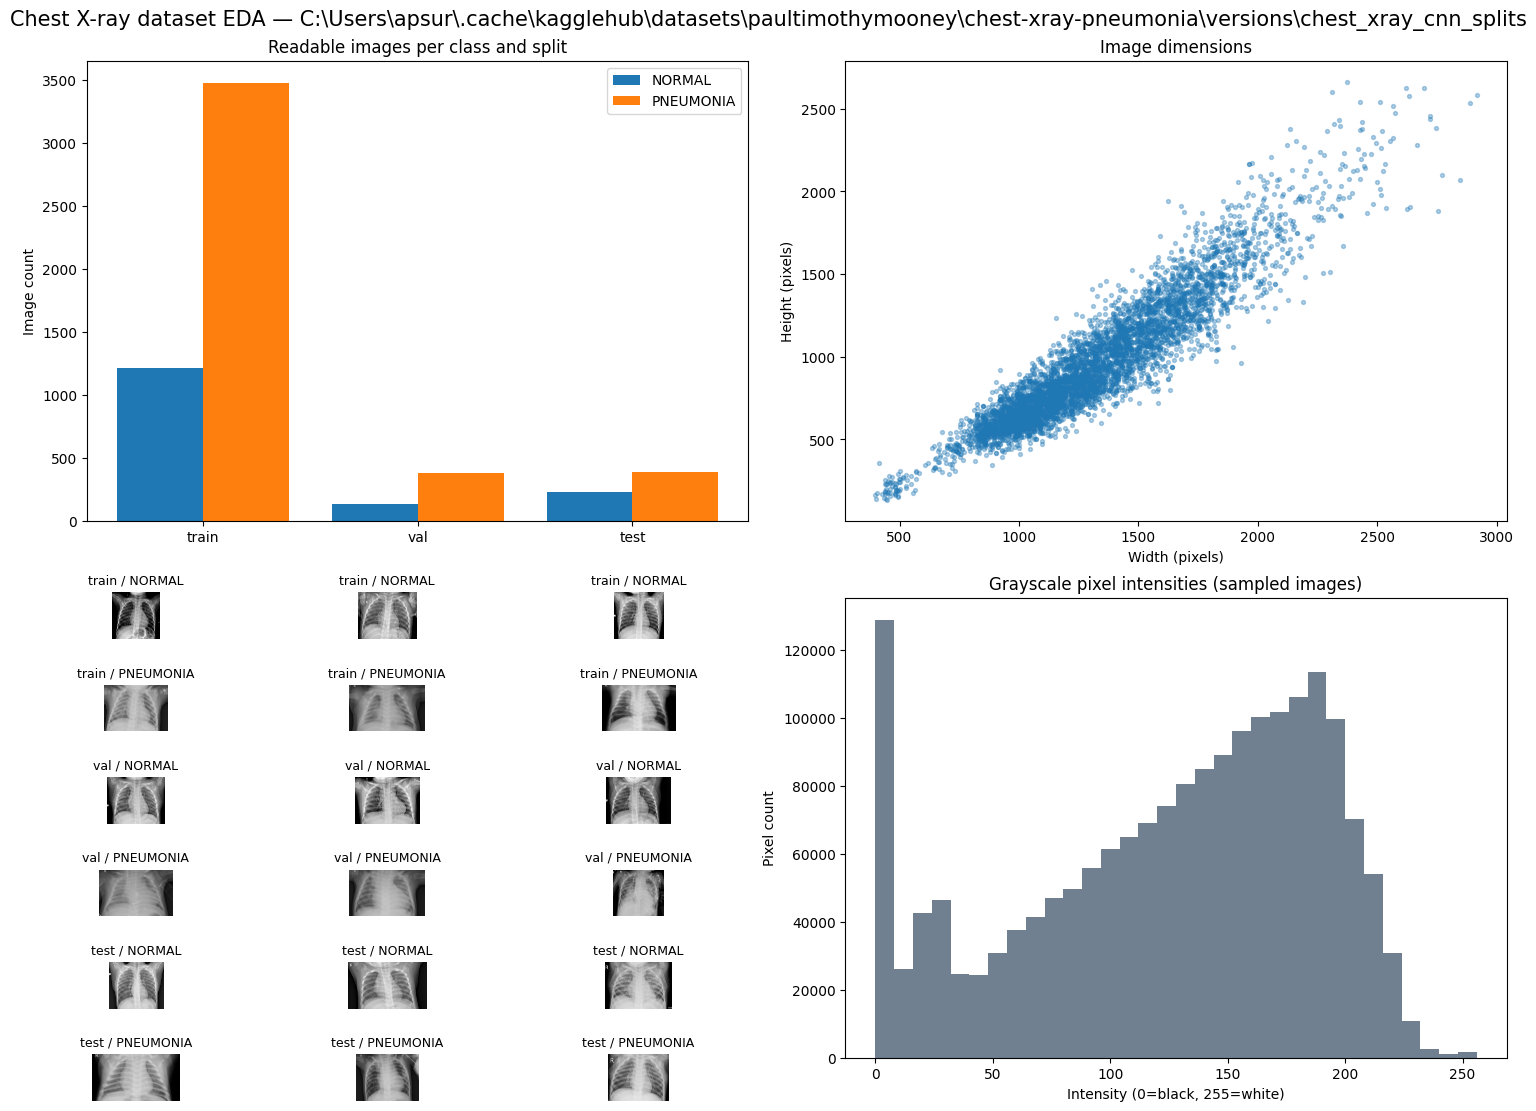

Saved figure to: C:\dev\Cnn\Cnn\xray-vision-pneumonia-CNN\data_eda.png


In [9]:
# Create a four-panel EDA figure.
fig = plt.figure(figsize=(15, 11), constrained_layout=True)
grid = fig.add_gridspec(2, 2)

# Class balance per split.
ax_counts = fig.add_subplot(grid[0, 0])
split_names = list(valid_records)
x = np.arange(len(split_names))
bar_width = 0.8 / max(len(class_names), 1)
for index, class_name in enumerate(class_names):
    values = [counts[(split, class_name)] for split in split_names]
    ax_counts.bar(
        x + index * bar_width, values, bar_width,
        label=class_name, color=plt.get_cmap("tab10")(index)
    )
ax_counts.set_xticks(x + bar_width * (len(class_names) - 1) / 2, split_names)
ax_counts.set_title("Readable images per class and split")
ax_counts.set_ylabel("Image count")
ax_counts.legend()

# Width versus height for all readable images (subsample if very large).
ax_dimensions = fig.add_subplot(grid[0, 1])
shown_dimensions = image_dimensions
if len(shown_dimensions) > 5000:
    shown_dimensions = random.Random(SEED).sample(shown_dimensions, 5000)
if shown_dimensions:
    widths, heights = zip(*shown_dimensions)
    ax_dimensions.scatter(widths, heights, s=8, alpha=0.35)
ax_dimensions.set_title("Image dimensions")
ax_dimensions.set_xlabel("Width (pixels)")
ax_dimensions.set_ylabel("Height (pixels)")

# Sample images from available split/class combinations.
if samples:
    rows = (len(samples) + 2) // 3
    subgrid = grid[1, 0].subgridspec(rows, 3, wspace=0.05, hspace=0.15)
    for index, (split, class_name, image_path) in enumerate(samples):
        ax = fig.add_subplot(subgrid[index // 3, index % 3])
        with Image.open(image_path) as image:
            ax.imshow(image.convert("L"), cmap="gray")
        ax.set_title(f"{split} / {class_name}", fontsize=9)
        ax.axis("off")
else:
    ax_samples = fig.add_subplot(grid[1, 0])
    ax_samples.text(0.5, 0.5, "No sample images available", ha="center", va="center")
    ax_samples.axis("off")

# Pixel intensity distribution for sampled images.
ax_intensity = fig.add_subplot(grid[1, 1])
intensity_samples = []
for _, _, image_path in samples:
    with Image.open(image_path) as image:
        pixels = np.asarray(image.convert("L"))
        if pixels.size > 100_000:
            pixels = pixels.ravel()[:: max(1, pixels.size // 100_000)]
        intensity_samples.append(pixels.ravel())
if intensity_samples:
    ax_intensity.hist(np.concatenate(intensity_samples), bins=32, range=(0, 256), color="slategray")
ax_intensity.set_title("Grayscale pixel intensities (sampled images)")
ax_intensity.set_xlabel("Intensity (0=black, 255=white)")
ax_intensity.set_ylabel("Pixel count")

fig.suptitle(f"Chest X-ray dataset EDA — {DATA_DIR}", fontsize=15)
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(OUTPUT_PATH, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved figure to: {OUTPUT_PATH.resolve()}")

## Reading the results

- Compare class counts across splits before training; validation and test should remain representative of the original data.
- Check image dimensions and modes for unexpected inconsistencies before choosing model preprocessing.
- Inspect examples and pixel distributions for unreadable files, artifacts, and visual differences.
- This notebook only reports exact file readability and simple image metadata; it does not diagnose images or detect near-duplicate patients.